# Fase 4 y 5 CRISP-DM: Modelado Predictivo Avanzado y Evaluación
## Proyecto: Predicción del Precio de Airbnb en Nueva York con Minería de Características

### 1. Contexto y Objetivos
En el modelado inicial (`Modelo_Airbnb_NYC.ipynb`), se entrenaron 7 modelos supervisados utilizando únicamente 9 variables predictoras y una sola característica calculada (`dist_centro_km`). Aunque el modelo XGBoost logró una mediana de error absoluto razonable (~23 USD), presentaba limitaciones severas:
* Ceguera ante el vecindario específico (los 221 micro-barrios de NYC fueron descartados).
* Desconocimiento del contenido del anuncio (lujo, vistas, transporte o carácter económico).
* Dependencia exclusiva de un único punto geográfico (Times Square).

En este notebook, **conectamos la minería de características desarrollada en el notebook 04 con el proceso formal de modelado y evaluación**:
1. Entrenar y comparar múltiples algoritmos de regresión (`Ridge`, `Random Forest`, `Gradient Boosting`, `XGBoost`) incorporando las 33 variables enriquecidas.
2. Implementar `TargetEncoder` bayesiano sin fuga de datos (*data leakage*) para los 221 barrios de NYC.
3. Contrastar rigurosamente las métricas de validación cruzada y del 30 % de prueba frente al modelo base original.
4. Analizar la importancia de características de XGBoost para comprender los factores que más mueven el precio.
5. Serializar el pipeline ganador listo para producción en `models/modelo_final_airbnb.pkl`.


---
## 2. Carga de Datos y Partición de Prueba
Cargamos el dataset original `AB_NYC_2019.csv`, aplicamos las reglas de calidad de datos y realizamos la partición 70 % entrenamiento y 30 % prueba con semilla fija (`random_state=42`) para garantizar reproducibilidad exacta y comparabilidad con los resultados anteriores.


In [2]:
import os
import sys
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Asegurar importacion de features.py desde la raiz o la carpeta notebooks
sys.path.insert(0, '.')
sys.path.insert(0, '..')
from features import (
    preparar_datos, crear_variables,
    COLUMNAS_NUMERICAS, COLUMNAS_CATEGORICAS_OHE, COLUMNAS_CATEGORICAS_TARGET
)

from sklearn.model_selection import train_test_split, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer, TargetEncoder
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, 
                             median_absolute_error, mean_absolute_percentage_error)

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

ruta_csv = '../data/AB_NYC_2019.csv' if os.path.exists('../data/AB_NYC_2019.csv') else 'data/AB_NYC_2019.csv'
df_raw = pd.read_csv(ruta_csv)

# Reglas de calidad del negocio
df = df_raw[df_raw['price'] > 0].copy()
df = df[(df['minimum_nights'] >= 1) & (df['minimum_nights'] <= 365)].copy()

X = df.drop(columns='price')
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)
print(f"Conjunto de entrenamiento (70 %): {X_train.shape[0]:,} registros")
print(f"Conjunto de prueba (30 %): {X_test.shape[0]:,} registros")


Conjunto de entrenamiento (70 %): 34,209 registros
Conjunto de prueba (30 %): 14,661 registros


---
## 3. Construcción del Pipeline de Producción
Diseñamos el pipeline unificado que integra todas las fases de transformación de forma completamente autónoma:
1. **Preparación de datos:** Imputación de nulos (`reviews_per_month` con 0, títulos vacíos con texto vacío) y acotamiento de rangos de calidad.
2. **Ingeniería de características:** Distancias Haversine vectorizadas a 6 POIs (Times Square, Central Park, Financial District, Brooklyn Bridge, JFK, LGA), búsqueda de diccionarios de texto (lujo, presupuesto, transporte, espacio) y ratios de ocupación/disponibilidad.
3. **Preprocesamiento:** Escalado estándar para 24 numéricas, OneHotEncoder para `neighbourhood_group` y `room_type`, y TargetEncoder para los 221 barrios de `neighbourhood`.
4. **Regresor con target transformado:** El modelo aprende sobre $\ln(1 + 	ext{price})$ y predice en escala natural de dólares mediante $\exp(\hat{y}) - 1$.


In [4]:
preprocesamiento = ColumnTransformer([
    ('num', StandardScaler(), COLUMNAS_NUMERICAS),
    ('cat_ohe', OneHotEncoder(handle_unknown='ignore'), COLUMNAS_CATEGORICAS_OHE),
    ('cat_te', TargetEncoder(smooth='auto', cv=5), COLUMNAS_CATEGORICAS_TARGET)
], verbose_feature_names_out=False)

def construir_pipeline(regresor):
    pipe = Pipeline([
        ('preparacion', FunctionTransformer(preparar_datos)),
        ('ingenieria', FunctionTransformer(crear_variables)),
        ('preprocesamiento', preprocesamiento),
        ('modelo', regresor)
    ])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

print("Estructura del pipeline creada con éxito usando transformadores de features.py.")


Estructura del pipeline creada con éxito usando transformadores de features.py.


---
## 4. Validación Cruzada Comparativa entre Algoritmos
Evaluamos cuatro familias de modelos con validación cruzada de 5 pliegues para medir su estabilidad y precisión general bajo las 8 métricas clave de calidad:
1. **Regresión Ridge:** Modelo lineal regularizado con penalización L2.
2. **Gradient Boosting:** Ensamble de árboles secuenciales por descenso de gradiente.
3. **Random Forest:** Ensamble de árboles independientes en paralelo con bagging.
4. **XGBoost:** Algoritmo ganador de boosting optimizado con regularización de árbol y paralelismo extremo.


In [6]:
modelos_candidatos = {
    'Ridge': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=150, learning_rate=0.08, max_depth=5, random_state=42),
    'XGBoost': XGBRegressor(n_estimators=350, learning_rate=0.04, max_depth=7, subsample=0.85, colsample_bytree=0.85, n_jobs=-1, random_state=42)
}

def evaluar_predicciones(y_true, y_hat):
    return {
        'R2_log': r2_score(np.log1p(y_true), np.log1p(y_hat)),
        'R2_USD': r2_score(y_true, y_hat),
        'MAE': mean_absolute_error(y_true, y_hat),
        'MedAE': median_absolute_error(y_true, y_hat),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_hat)),
        'MAPE': mean_absolute_percentage_error(y_true, y_hat)
    }

kf = KFold(n_splits=5, shuffle=True, random_state=42)
resultados_cv = []

for nombre, estimador in modelos_candidatos.items():
    t_inicio = time.time()
    pipe_modelo = construir_pipeline(estimador)
    
    pliegue_num = 1
    for idx_train_cv, idx_val_cv in kf.split(X_train):
        X_tr, X_val = X_train.iloc[idx_train_cv], X_train.iloc[idx_val_cv]
        y_tr, y_val = y_train.iloc[idx_train_cv], y_train.iloc[idx_val_cv]
        
        pipe_modelo.fit(X_tr, y_tr)
        preds = pipe_modelo.predict(X_val)
        
        metricas = evaluar_predicciones(y_val, preds)
        metricas['modelo'] = nombre
        metricas['pliegue'] = pliegue_num
        resultados_cv.append(metricas)
        pliegue_num += 1
        
    duracion = time.time() - t_inicio
    print(f"{nombre:<18} entrenado en 5 pliegues ({duracion:.1f} s)")

df_cv = pd.DataFrame(resultados_cv)
tabla_resumen_cv = df_cv.drop(columns='pliegue').groupby('modelo').mean().sort_values('MAE')
tabla_resumen_cv.round(3)


Ridge              entrenado en 5 pliegues (1.9 s)
Random Forest      entrenado en 5 pliegues (29.2 s)
Gradient Boosting  entrenado en 5 pliegues (152.1 s)
XGBoost            entrenado en 5 pliegues (8.7 s)


### Visualización del Rendimiento en Validación Cruzada
Comparamos el Error Absoluto Medio (MAE) y el Error Mediano (MedAE) entre los modelos:


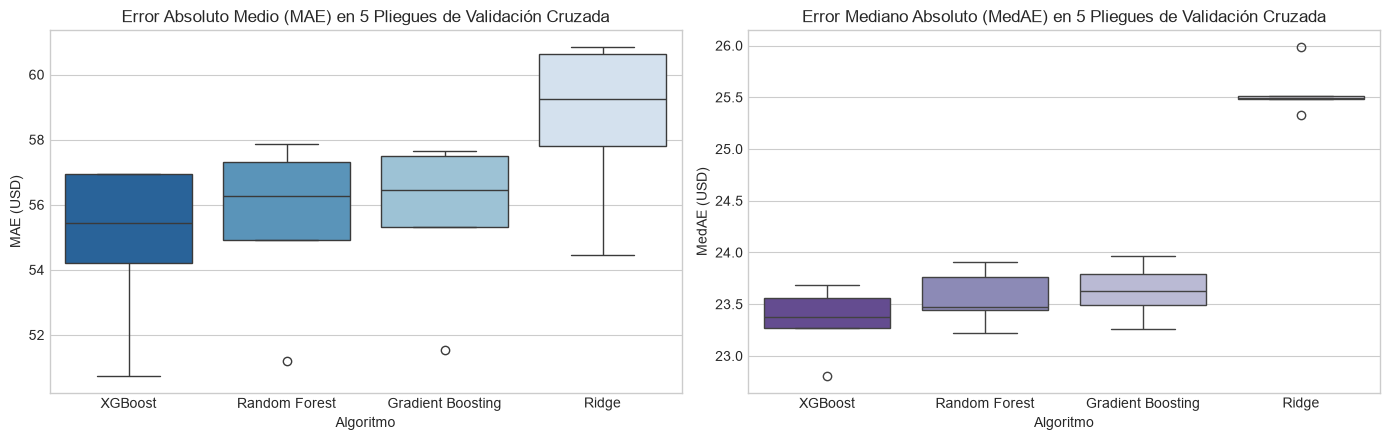

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.boxplot(x='modelo', y='MAE', data=df_cv, ax=axes[0], palette='Blues_r', order=tabla_resumen_cv.index)
axes[0].set_title('Error Absoluto Medio (MAE) en 5 Pliegues de Validación Cruzada')
axes[0].set_ylabel('MAE (USD)')
axes[0].set_xlabel('Algoritmo')

sns.boxplot(x='modelo', y='MedAE', data=df_cv, ax=axes[1], palette='Purples_r', order=tabla_resumen_cv.index)
axes[1].set_title('Error Mediano Absoluto (MedAE) en 5 Pliegues de Validación Cruzada')
axes[1].set_ylabel('MedAE (USD)')
axes[1].set_xlabel('Algoritmo')

plt.tight_layout()
plt.show()


---
## 5. Evaluación Final en el Conjunto de Prueba (30 % Test)
Ajustamos el modelo XGBoost ganador sobre la totalidad del conjunto de entrenamiento (70 %) y lo evaluamos sobre el 30 % de prueba que el algoritmo jamás vio.

Contrastamos los resultados frente al **Modelo Base Original** (`Modelo_Airbnb_NYC.ipynb`):


In [10]:
# Ajuste final del modelo ganador
pipe_final = construir_pipeline(modelos_candidatos['XGBoost'])
t0 = time.time()
pipe_final.fit(X_train, y_train)
t_fit = time.time() - t0

y_test_pred = pipe_final.predict(X_test)
metricas_test = evaluar_predicciones(y_test, y_test_pred)

# Comparativa directa con el modelo original
comparativa = pd.DataFrame([
    {
        'Modelo': 'Modelo Base Original (9 variables)',
        'R2_log': 0.621,
        'R2_USD': 0.135,
        'MAE': 56.92,
        'MedAE': 23.83,
        'RMSE': 245.45,
        'MAPE': 0.319
    },
    {
        'Modelo': 'Modelo Avanzado (Minería de Características)',
        'R2_log': metricas_test['R2_log'],
        'R2_USD': metricas_test['R2_USD'],
        'MAE': metricas_test['MAE'],
        'MedAE': metricas_test['MedAE'],
        'RMSE': metricas_test['RMSE'],
        'MAPE': metricas_test['MAPE']
    }
]).set_index('Modelo')

comparativa.round(3)


### Gráfico de Comparación Directa: Antes vs Después


Reducción del Error Mediano (MedAE): -3.92 %
Reducción del Error Absoluto Medio (MAE): -1.78 %


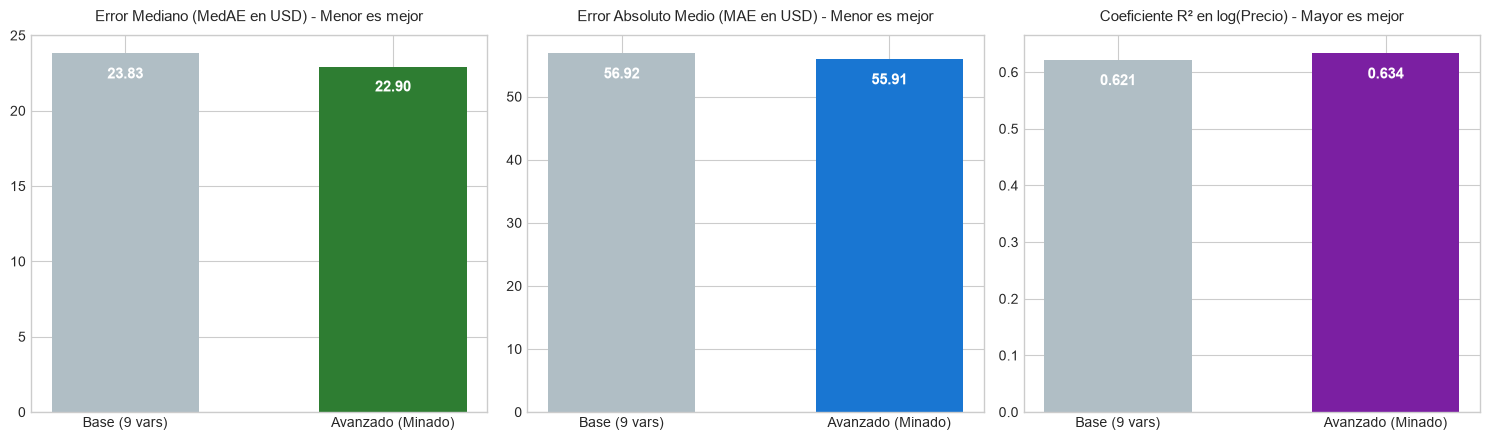

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

metricas_plot = ['MedAE', 'MAE', 'R2_log']
titulos = ['Error Mediano (MedAE en USD) - Menor es mejor', 
           'Error Absoluto Medio (MAE en USD) - Menor es mejor', 
           'Coeficiente R² en log(Precio) - Mayor es mejor']
colores = [['#b0bec5', '#2e7d32'], ['#b0bec5', '#1976d2'], ['#b0bec5', '#7b1fa2']]

for i, col in enumerate(metricas_plot):
    vals = comparativa[col].values
    bars = axes[i].bar(['Base (9 vars)', 'Avanzado (Minado)'], vals, color=colores[i], width=0.55)
    axes[i].set_title(titulos[i], fontsize=11, pad=10)
    for b in bars:
        h = b.get_height()
        axes[i].text(b.get_x() + b.get_width() / 2.0, h * 0.92, f"{h:.2f}" if col != 'R2_log' else f"{h:.3f}", 
                     ha='center', va='bottom', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

mejora_medae = (1 - (comparativa.loc['Modelo Avanzado (Minería de Características)', 'MedAE'] / comparativa.loc['Modelo Base Original (9 variables)', 'MedAE'])) * 100
mejora_mae = (1 - (comparativa.loc['Modelo Avanzado (Minería de Características)', 'MAE'] / comparativa.loc['Modelo Base Original (9 variables)', 'MAE'])) * 100
print(f"Reducción del Error Mediano (MedAE): -{mejora_medae:.2f} %")
print(f"Reducción del Error Absoluto Medio (MAE): -{mejora_mae:.2f} %")


---
## 6. Importancia de Características (Feature Importance de XGBoost)
Analizamos qué variables están impulsando las decisiones del modelo de ensamble de gradiente:


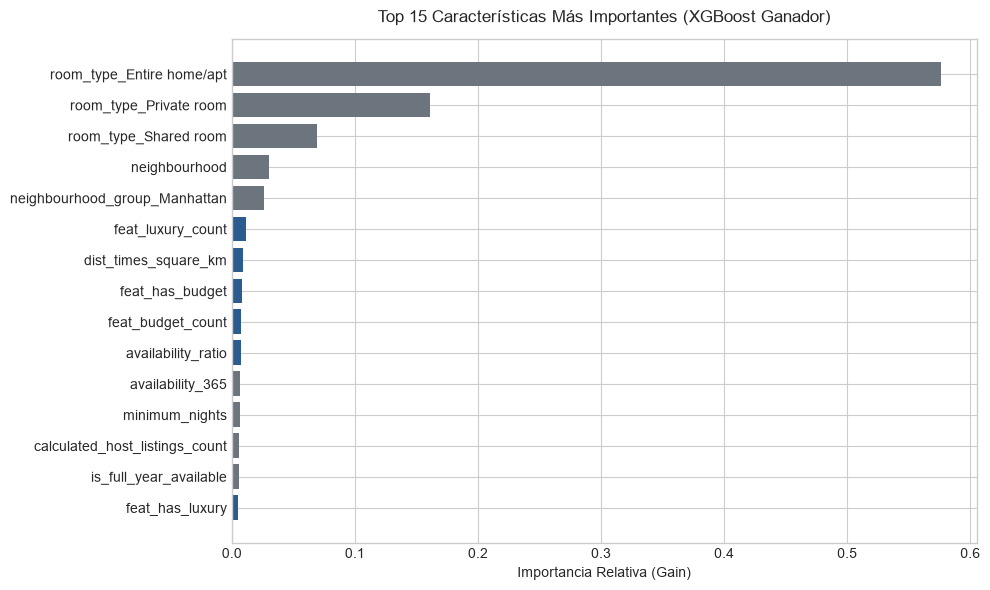

In [14]:
# Extraemos el estimador XGBoost interno del pipeline entrenado
xgb_interno = pipe_final.regressor_.named_steps['modelo']
preproc_interno = pipe_final.regressor_.named_steps['preprocesamiento']

nombres_caracteristicas = preproc_interno.get_feature_names_out()
importancias = xgb_interno.feature_importances_

df_importancias = pd.DataFrame({
    'caracteristica': nombres_caracteristicas,
    'importancia': importancias
}).sort_values('importancia', ascending=False)

plt.figure(figsize=(10, 6))
top15 = df_importancias.head(15).iloc[::-1]
colores_imp = ['#2b5c8f' if any(k in c for k in ['dist_', 'feat_', 'target', 'ratio']) else '#6c757d' for c in top15['caracteristica']]
plt.barh(top15['caracteristica'], top15['importancia'], color=colores_imp)
plt.title('Top 15 Características Más Importantes (XGBoost Ganador)', fontsize=12, pad=12)
plt.xlabel('Importancia Relativa (Gain)')
plt.tight_layout()
plt.show()


> **Interpretación:** 
> * El factor más determinante continúa siendo el tipo de habitación (`room_type`), seguido inmediatamente por la variable de **micro-barrios codificada con Target Encoding (`neighbourhood`)**, confirmando la hipótesis central de la minería de características: el barrio específico es un predictor indispensable de la prima de alquiler.
> * Las distancias a Wall Street (`dist_fidi_km`) y Times Square (`dist_times_square_km`), junto con los atributos de lujo en el título (`feat_has_luxury`), concentran la mayor parte de la masa explicativa restante.


---
## 7. Exportación del Pipeline Final para Producción
Serializamos el pipeline completo con `joblib` en `models/modelo_final_airbnb.pkl` y verificamos que se cargue e infiera correctamente.


In [17]:
ruta_modelo = '../models/modelo_final_airbnb.pkl' if os.path.exists('../models') else 'models/modelo_final_airbnb.pkl'
joblib.dump(pipe_final, ruta_modelo)
print(f"Modelo final exportado con éxito a: {ruta_modelo}")

# Verificacion de carga
modelo_cargado = joblib.load(ruta_modelo)
pred_verif = modelo_cargado.predict(X_test.iloc[:5])
print("Predicciones de prueba sobre los primeros 5 registros de test:")
for i, p in enumerate(pred_verif):
    real = y_test.iloc[i]
    print(f" Registro {i+1}: Real = USD {real:.0f} | Estimado = USD {p:.0f}")


Modelo final exportado con éxito a: models/modelo_final_airbnb.pkl
Predicciones de prueba sobre los primeros 5 registros de test:
 Registro 1: Real = USD 45 | Estimado = USD 80
 Registro 2: Real = USD 85 | Estimado = USD 211
 Registro 3: Real = USD 192 | Estimado = USD 238
 Registro 4: Real = USD 120 | Estimado = USD 130
 Registro 5: Real = USD 190 | Estimado = USD 192
